# 03 - Live first-innings score prediction

**Why this notebook exists.** Notebook 02 tried to predict the first-innings total *before the match*
(venue, teams, toss, season). After ~100 steps the best model reached MAE ~27 runs and R2 ~ 0.
That is not a bug - it is the ceiling of those inputs (see the diagnosis below).
The fix is to change the *question*: predict the final total **from the match state at the end of each over**
(runs, wickets, recent scoring) using the ball-by-ball data you already parsed.

## Experiment log (notebook 02)

| # | Technique | Result (MAE, runs) | Verdict |
|---|-----------|-------------------|---------|
| 1 | Fixed train-mean baseline (80/20 chrono split) | 37.1 | Weak: ignores scoring era |
| 2 | Rolling previous-3-seasons mean | 31.5 | Big jump, from *era* info only |
| 3 | Ridge (season, venue, city, teams, toss) | 31.7 | No gain over #2 |
| 4 | Random Forest, same features | 31.2 | Tiny gain |
| 5 | RF + team batting form | 32.7 | **Worse**: noise |
| 6 | Recency-weighted mean (decay 0.990-0.998) | 33.1-35.7 | Worse than rolling windows: too much old history |
| 7 | RF + league scoring trend | 32.3 | Worse |
| 8 | Season-only RF | 30.6 | Season alone beats full RF |
| 9 | Linear season trend | 32.4 | Cannot follow the 2023+ jump |
| 10 | Rolling last-30-match mean | 30.3 | Best simple model |
| 11 | Date-safe rolling baseline (same-day leak fix) | 30.3 | Correct fix, same score |
| 12 | RF + team/venue history | 32.0 | Worse |
| 13 | HistGradientBoosting | 30.6 | ~ baseline |
| 14 | Rolling-origin folds 2021-24 + 2025-26 holdout | - | **Right validation design** |
| 15 | Recent-30 vs 70/30 blend with previous seasons | 27.5 / 27.2 | Blend wins 1 of 4 seasons |
| 16 | Venue-name standardisation (60 -> 49 venues) | 27.3 -> 27.0 | Correct, small gain |
| 17 | Champion RF (standardised base) | 27.0 | Beats recent-30 (27.5) by 0.5 run |
| 18 | + team form / + team history / + bowling history / + league environment | 27.5-29.3 | All worse than #17 |
| 19 | Gradient Boosting (huber) | 26.9 | Same as RF within noise |
| 20 | Error analysis | - | Predictions squeezed to 146-203 vs actual 68-287 |

> **Careful when comparing:** rows 1-13 were scored on one 80/20 split (test = 2023-05 to 2026, MAE ~30-37).
> Rows 14+ use rolling folds validated on 2021-24 (MAE ~27). The drop from ~31 to ~27 is mostly a *different, easier test set*,
> not a better model. Compare numbers only inside the same block.

## Diagnosis - why predictions never "got right"

1. **Ceiling.** Pre-match, the first-innings score has std ~ 31-38 runs. Venue/teams/toss explain only a few % of it.
   MAE ~ 0.8 x std ~ 25-27 *is what a good pre-match model looks like*.
2. **Regression to the mean.** Prediction std was 2-11 runs vs actual 29-39. Models always say "~165-175".
   Result: 200+ scores under-predicted by ~47, sub-120 scores over-predicted by ~67.
3. **Regime shift.** Mean score went ~160-172 (2017-22) -> 183 (2023) -> 190 (2024). Trees using `season` as a number cannot
   extrapolate, so 2023 mean residual was +17 runs.
4. **Tiny validation.** 60-74 matches per fold, MAE standard error ~ 2-3 runs. Most "improvements/degradations" above
   (0.3-1 run) are inside noise, so adding features looked random.
5. **Redundant / weak features.** `batting_team_won_toss` is identical to `toss_decision == "bat"` in this data (418 / 825 both);
   `city` duplicates `venue`; ~120 one-hot columns for ~1,000 rows. Team name is a poor proxy for team strength (squads change every auction).
6. **Unused data.** 295k ball-by-ball rows were used only for EDA, never for the model.

## Fix in this notebook
* One row per (match, end-of-over k), k = 1..19.
* Target = **remaining runs** (final - runs so far), prediction = runs so far + remaining.
* Era handled with a *leak-safe* "recent league average" feature instead of `season`.
* Season-based rolling-origin validation (all rows of a match stay on the same side), 2025-26 touched once.
* Honest reporting: MAE **by over**, plus an 80% prediction range.

In [4]:
import os, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

# Same convention as notebooks 01/02: notebook lives in /notebooks, data in /data/raw
PROJECT_ROOT = Path(os.environ.get("IPL_PROJECT_ROOT", Path.cwd().parent))
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("YAML files  :", len(list(RAW_DATA_DIR.glob("*.yaml"))))

Project root: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab
YAML files  : 1243


## 1. Parse first innings ball-by-ball

In [5]:
# 'retired hurt' is not a lost wicket (the batter may return), so it is not counted.
NOT_A_WICKET = {"retired hurt", "retired not out"}


def iter_raw_deliveries(innings_data):
    # Yield raw delivery dicts for both Cricsheet layouts.
    if "deliveries" in innings_data:                       # layout used by your files
        for entry in innings_data["deliveries"]:
            if isinstance(entry, dict) and entry:
                yield next(iter(entry.values()))
    elif "overs" in innings_data:                          # newer layout
        for over in innings_data["overs"]:
            for d in over.get("deliveries", []):
                yield d
    else:
        raise ValueError("Unknown innings layout: %s" % list(innings_data))


def parse_delivery(d):
    runs = d.get("runs") or {}
    extras = d.get("extras") or {}
    wk = d.get("wickets")
    if wk is None:
        w = d.get("wicket")
        wk = [w] if isinstance(w, dict) else []
    return {
        "total": runs.get("total", 0) or 0,
        "batter": runs.get("batter", runs.get("batsman", 0)) or 0,
        "wide": extras.get("wides", 0) or 0,
        "noball": extras.get("noballs", 0) or 0,
        "wickets": sum(1 for w in wk if w.get("kind") not in NOT_A_WICKET),
    }


def over_end_states(deliveries):
    # {k: (runs, wickets, boundaries)} measured when the 6th LEGAL ball of over k is bowled.
    # Wides and no-balls are not legal balls, so they never close an over.
    runs = wkts = bnd = legal = 0
    states = {}
    for d in deliveries:
        runs += d["total"]
        wkts += d["wickets"]
        if d["batter"] in (4, 6) and d["wide"] == 0:
            bnd += 1
        if d["wide"] == 0 and d["noball"] == 0:
            legal += 1
            if legal % 6 == 0:
                states[legal // 6] = (runs, wkts, bnd)
    return states, runs, wkts, legal


def load_first_innings(raw_dir):
    rows, states_by_match, errors = [], {}, []
    for path in sorted(raw_dir.glob("*.yaml")):
        try:
            with path.open("r", encoding="utf-8") as f:
                match = yaml.safe_load(f)
            info = match["info"]
            first = None
            for entry in match.get("innings", []):
                name, data = next(iter(entry.items()))
                if name == "1st innings":              # skips 2nd innings and Super Overs
                    first = data
                    break
            if first is None:
                continue
            deliveries = [parse_delivery(d) for d in iter_raw_deliveries(first)]
            states, final, wkts, legal = over_end_states(deliveries)
            rows.append({
                "match_id": path.stem,
                "date": pd.to_datetime(str(info["dates"][0])),
                "venue_raw": info.get("venue"),
                "batting_team": first.get("team"),
                "scheduled_overs": info.get("overs", 20),
                "final_score": final,
                "final_wickets": wkts,
                "legal_balls": legal,
            })
            states_by_match[path.stem] = states
        except Exception as exc:
            errors.append((path.name, repr(exc)))
    return pd.DataFrame(rows), states_by_match, errors


matches, states_by_match, load_errors = load_first_innings(RAW_DATA_DIR)
print("Matches parsed :", len(matches))
print("Load errors    :", len(load_errors), load_errors[:3])

Matches parsed : 1243
Load errors    : 0 []


In [6]:
# Keep only complete 20-over first innings (or all out). Rain-shortened innings have a different target.
matches["complete"] = (
    (matches["scheduled_overs"] == 20)
    & ((matches["legal_balls"] >= 120) | (matches["final_wickets"] >= 10))
)
print("Dropped (shortened / curtailed first innings):", int((~matches["complete"]).sum()))
matches = matches[matches["complete"]].drop(columns="complete").reset_index(drop=True)
matches["season"] = matches["date"].dt.year


# --- venue names: strip ', City' suffix + known renames (extend the alias dict if you spot more) ---
VENUE_ALIASES = {
    "feroz shah kotla": "Arun Jaitley Stadium",
    "sardar patel stadium": "Narendra Modi Stadium",
    "sheikh zayed stadium": "Zayed Cricket Stadium",
    "punjab cricket association stadium": "Punjab Cricket Association IS Bindra Stadium",
    "punjab cricket association is bindra stadium": "Punjab Cricket Association IS Bindra Stadium",
    "subrata roy sahara stadium": "Maharashtra Cricket Association Stadium",
}

def standardize_venue(v):
    if not isinstance(v, str):
        return "Unknown"
    key = re.sub(r"\s+", " ", v.split(",")[0].replace(".", " ")).strip().lower()
    return VENUE_ALIASES.get(key, re.sub(r"\s+", " ", v.split(",")[0].replace(".", " ")).strip())

matches["venue"] = matches["venue_raw"].map(standardize_venue)
print("Venue labels: raw %d -> standardised %d" % (matches["venue_raw"].nunique(), matches["venue"].nunique()))
print(matches["venue"].value_counts().head(8).to_string())
print("\nVenues with < 5 matches (check these for missed aliases):")
print(matches["venue"].value_counts().loc[lambda s: s < 5].to_string())

Dropped (shortened / curtailed first innings): 28
Venue labels: raw 60 -> standardised 36
venue
Wankhede Stadium                                132
Eden Gardens                                    102
Arun Jaitley Stadium                            101
MA Chidambaram Stadium                           98
M Chinnaswamy Stadium                            97
Rajiv Gandhi International Stadium               89
Sawai Mansingh Stadium                           66
Punjab Cricket Association IS Bindra Stadium     60

Venues with < 5 matches (check these for missed aliases):
venue
Green Park                              4
Nehru Stadium                           4
Buffalo Park                            3
De Beers Diamond Oval                   3
Vidarbha Cricket Association Stadium    3
OUTsurance Oval                         2


## 2. Leak-safe pre-match context
Only matches with `date <` the current match date are used (same-day matches never see each other).
Venue average is **shrunk** toward the league average so a venue with 2 matches does not get a wild value.

In [7]:
def add_prior_context(df, league_window=60, venue_shrink=5.0, fallback=160.0):
    m = df.sort_values(["date", "match_id"]).reset_index(drop=True).copy()
    dates = m["date"].to_numpy()
    totals = m["final_score"].to_numpy(dtype=float)
    venues = m["venue"].to_numpy()

    league, venue_prior, venue_n = [], [], []
    for i in range(len(m)):
        prior = np.flatnonzero(dates < dates[i])                    # strictly earlier dates only
        recent = totals[prior][-league_window:]
        lg = recent.mean() if len(recent) >= 5 else fallback
        same_venue = prior[venues[prior] == venues[i]]
        n = len(same_venue)
        s = totals[same_venue].sum()
        league.append(lg)
        venue_n.append(n)
        venue_prior.append((s + venue_shrink * lg) / (n + venue_shrink))
    m["league_recent"] = league
    m["venue_prior"] = venue_prior
    m["venue_n"] = venue_n
    return m


matches = add_prior_context(matches)
matches[["venue", "final_score", "league_recent", "venue_prior", "venue_n"]].tail(5).round(1)

,venue,final_score,league_recent,venue_prior,venue_n
1210,Eden Gardens,203,196.2,172.7,101
1211,Himachal Pradesh Cricket Association Stadium,254,195.8,192.5,17
1212,Maharaja Yadavindra Singh International Cricke...,243,197.3,185.1,15
1213,Maharaja Yadavindra Singh International Cricke...,214,197.9,188.0,16
1214,Narendra Modi Stadium,155,198.8,182.7,52


## 3. One row per (match, end of over k)
Features use only balls already bowled. Target = runs still to come.

In [8]:
TOTAL_OVERS = 20


def snapshot_features(states, k):
    # Features at the end of over k. Reads states[j] for j <= k ONLY (checked by the leak test below).
    runs, wkts, bnd = states[k]
    prev = states[k - 5][0] if (k - 5) >= 1 else 0
    last5_overs = min(k, 5)
    runs_last5 = runs - prev
    prev_w = states[k - 5][1] if (k - 5) >= 1 else 0
    return {
        "over": k,
        "overs_left": TOTAL_OVERS - k,
        "runs": runs,
        "wickets": wkts,
        "wickets_in_hand": 10 - wkts,
        "run_rate": runs / k,
        "runs_last5": runs_last5,
        "wkts_last5": wkts - prev_w,
        "rr_last5": runs_last5 / last5_overs,
        "boundaries": bnd,
    }


def build_snapshots(matches, states_by_match, overs=range(1, TOTAL_OVERS)):
    rows = []
    for r in matches.itertuples():
        states = states_by_match[r.match_id]
        for k in overs:
            if k not in states:            # innings ended (all out) before this over
                continue
            f = snapshot_features(states, k)
            f.update(match_id=r.match_id, date=r.date, season=r.season,
                     venue_prior=r.venue_prior, venue_n=r.venue_n, league_recent=r.league_recent,
                     final_score=r.final_score)
            rows.append(f)
    snap = pd.DataFrame(rows)
    snap["remaining"] = snap["final_score"] - snap["runs"]
    return add_linear_terms(snap)


def add_linear_terms(df):
    # linear-friendly "expected remaining" terms: rate x overs left
    df = df.copy()
    L = df["overs_left"]
    df["crr_remaining"] = df["run_rate"] * L
    df["form_remaining"] = df["rr_last5"] * L
    df["league_remaining"] = df["league_recent"] / TOTAL_OVERS * L
    df["venue_remaining"] = df["venue_prior"] / TOTAL_OVERS * L
    df["hand_x_left"] = df["wickets_in_hand"] * L
    return df


snap = build_snapshots(matches, states_by_match)
print("Snapshot rows:", len(snap), "| matches:", snap["match_id"].nunique())
snap.drop(columns=["date"]).head(3).round(2)

Snapshot rows: 23013 | matches: 1215


,over,overs_left,runs,wickets,wickets_in_hand,run_rate,runs_last5,wkts_last5,rr_last5,boundaries,...,venue_prior,venue_n,league_recent,final_score,remaining,crr_remaining,form_remaining,league_remaining,venue_remaining,hand_x_left
0,1,19,3,0,10,3.0,3,0,3.0,0,...,160.0,0,160.0,222,219,57.0,57.0,152.0,152.0,190
1,2,18,21,0,10,10.5,21,0,10.5,4,...,160.0,0,160.0,222,201,189.0,189.0,144.0,144.0,180
2,3,17,27,0,10,9.0,27,0,9.0,5,...,160.0,0,160.0,222,195,153.0,153.0,136.0,136.0,170


## 4. Leak tests (these must pass before any model is trusted)

In [9]:
rng = np.random.default_rng(0)

# (a) snapshot features at over k must not change if every later over is deleted
ids = rng.choice(matches["match_id"].to_numpy(), size=min(40, len(matches)), replace=False)
for mid in ids:
    states = states_by_match[mid]
    for k in [k for k in (3, 6, 10, 15, 19) if k in states]:
        full = snapshot_features(states, k)
        cut = snapshot_features({j: v for j, v in states.items() if j <= k}, k)
        assert full == cut, ("future information used", mid, k)
print("OK: over-k features use only balls up to over k")

# (b) pre-match context must not change if the current and all later matches are corrupted
probe = matches.sort_values("date").iloc[len(matches) // 2]
corrupt = matches.copy()
corrupt.loc[corrupt["date"] >= probe["date"], "final_score"] = 999
a = add_prior_context(matches).set_index("match_id").loc[probe["match_id"]]
b = add_prior_context(corrupt).set_index("match_id").loc[probe["match_id"]]
assert np.isclose(a["league_recent"], b["league_recent"]) and np.isclose(a["venue_prior"], b["venue_prior"])
print("OK: league/venue context uses only earlier dates")

# (c) totals rebuilt from the over-by-over states are consistent with the final score
bad = [mid for mid in states_by_match if mid in set(matches["match_id"])
       and states_by_match[mid].get(19, (0,))[0] > matches.set_index("match_id").loc[mid, "final_score"]]
assert not bad, bad[:5]
print("OK: runs after over 19 never exceed the final score")

OK: over-k features use only balls up to over k
OK: league/venue context uses only earlier dates
OK: runs after over 19 never exceed the final score


## 5. Models and validation
Rolling-origin by season (same four folds as notebook 02: validate 2021, 2022, 2023, 2024).
2025-26 stays untouched until the very end.

In [10]:
RAW_FEATS = ["over", "overs_left", "runs", "wickets", "wickets_in_hand", "run_rate",
             "runs_last5", "wkts_last5", "rr_last5", "boundaries",
             "venue_prior", "venue_n", "league_recent"]
LIN_FEATS = RAW_FEATS + ["crr_remaining", "form_remaining", "league_remaining",
                         "venue_remaining", "hand_x_left"]


class CRRProjection:
    # Naive projection: current run rate x 20 overs.
    name = "Run-rate x 20 (naive)"
    def fit(self, tr): return self
    def predict_final(self, df): return df["run_rate"].to_numpy() * TOTAL_OVERS


class ParByOverWickets:
    # Average 'runs still to come' from training data, given (over, wickets lost).
    name = "Par table (over, wickets)"
    def fit(self, tr):
        t = tr.assign(w=tr["wickets"].clip(upper=6))
        self.tab = t.groupby(["over", "w"])["remaining"].mean()
        self.by_over = t.groupby("over")["remaining"].mean()
        return self
    def predict_final(self, df):
        w = df["wickets"].clip(upper=6)
        rem = [self.tab.get((o, ww), self.by_over.get(o, np.nan)) for o, ww in zip(df["over"], w)]
        return df["runs"].to_numpy() + np.array(rem)


class RidgeRemaining:
    name = "Ridge"
    def fit(self, tr):
        self.m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10.0))
        self.m.fit(tr[LIN_FEATS], tr["remaining"])
        return self
    def predict_final(self, df): return df["runs"].to_numpy() + self.m.predict(df[LIN_FEATS])


def make_hgb(**kw):
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                         min_samples_leaf=60, l2_regularization=1.0, random_state=0, **kw)

class HGBRemaining:
    name = "Gradient boosting"
    def fit(self, tr):
        self.m = make_hgb().fit(tr[RAW_FEATS], tr["remaining"])
        return self
    def predict_final(self, df): return df["runs"].to_numpy() + self.m.predict(df[RAW_FEATS])


MODELS = [CRRProjection, ParByOverWickets, RidgeRemaining, HGBRemaining]

FOLDS = [{"train_through": y - 1, "validate": y} for y in (2021, 2022, 2023, 2024)]
FOLDS = [f for f in FOLDS if (snap["season"] == f["validate"]).any()]   # skip folds with no data
HOLDOUT_START = 2025
dev = snap[snap["season"] < HOLDOUT_START]
holdout = snap[snap["season"] >= HOLDOUT_START]
print("Dev rows:", len(dev), "| holdout rows:", len(holdout), "| folds:", [f["validate"] for f in FOLDS])

Dev rows: 20313 | holdout rows: 2700 | folds: [2021, 2022, 2023, 2024]


In [11]:
def run_folds(folds, data):
    out = []
    for f in folds:
        tr = data[data["season"] <= f["train_through"]]
        va = data[data["season"] == f["validate"]]
        for M in MODELS:
            model = M().fit(tr)
            pred = model.predict_final(va)
            out.append(va[["match_id", "over", "final_score"]].assign(
                model=model.name, pred=pred, fold=f["validate"]))
    return pd.concat(out, ignore_index=True)


dev_preds = run_folds(FOLDS, dev)
dev_preds["abs_err"] = (dev_preds["pred"] - dev_preds["final_score"]).abs()

CHECKPOINTS = [1, 3, 6, 10, 15, 18]
by_over = dev_preds.pivot_table(index="over", columns="model", values="abs_err", aggfunc="mean")
print("Pooled validation MAE (runs) by over, folds 2021-2024")
by_over.loc[CHECKPOINTS].round(1)

Pooled validation MAE (runs) by over, folds 2021-2024


model,Gradient boosting,"Par table (over, wickets)",Ridge,Run-rate x 20 (naive)
over,,,,
1,27.8,27.9,26.0,76.0
3,25.8,26.1,24.2,43.2
6,23.0,23.0,21.1,29.4
10,18.2,17.8,17.3,21.9
15,12.0,11.2,11.0,14.4
18,8.6,7.2,7.7,8.3


In [12]:
# Pre-match reference ("over 0"): what you can know before ball 1. Notebook 02's best model: ~27.0
pre = matches.copy()
pre = pre[pre["season"].isin([f["validate"] for f in FOLDS])]
pre_mae = (pre["final_score"] - pre["league_recent"]).abs().mean()
pre_mae_venue = (pre["final_score"] - pre["venue_prior"]).abs().mean()
print("Pre-match MAE using league_recent only: %.1f   | with shrunk venue average: %.1f   | notebook 02 RF: 27.0" % (pre_mae, pre_mae_venue))

overall = dev_preds.groupby("model")["abs_err"].mean().sort_values()
print("\nMean MAE over all overs (1-19):")
print(overall.round(2).to_string())

print("\nPer-fold MAE at over 6 / 10 / 15 for the best model:")
best_name = overall.index[0]
fold_view = (dev_preds[(dev_preds["model"] == best_name) & dev_preds["over"].isin([6, 10, 15])]
             .pivot_table(index="fold", columns="over", values="abs_err", aggfunc="mean").round(1))
fold_view

Pre-match MAE using league_recent only: 26.0   | with shrunk venue average: 27.5   | notebook 02 RF: 27.0

Mean MAE over all overs (1-19):
model
Ridge                        16.72
Par table (over, wickets)    17.51
Gradient boosting            17.95
Run-rate x 20 (naive)        26.37

Per-fold MAE at over 6 / 10 / 15 for the best model:


over,6,10,15
fold,,,
2021,23.1,17.7,11.4
2022,19.5,16.1,10.4
2023,18.5,17.2,10.6
2024,23.7,18.1,11.6


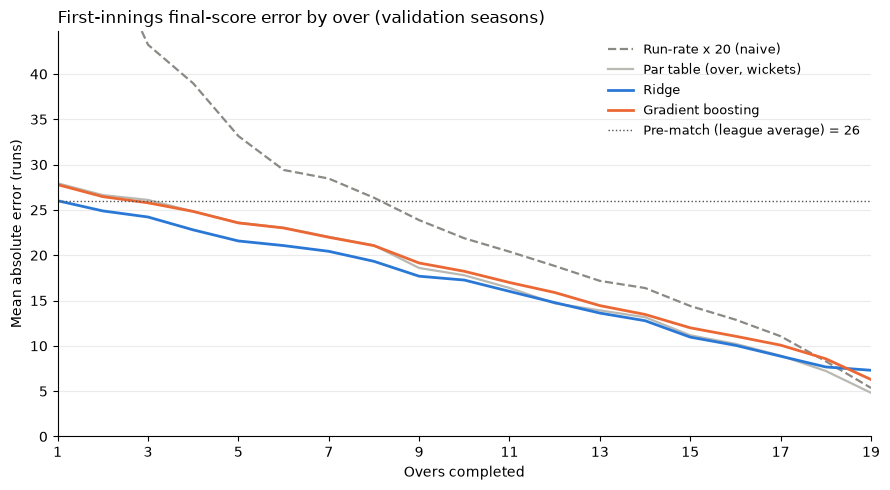

In [13]:
# ---- chart: MAE falls as the innings reveals itself ----
GRAY, GRAY2, BLUE, ORANGE = "#8a8984", "#b9b8b2", "#2a78d6", "#eb6834"
style = {
    "Run-rate x 20 (naive)": dict(color=GRAY, ls="--", lw=1.6),
    "Par table (over, wickets)": dict(color=GRAY2, ls="-", lw=1.6),
    "Ridge": dict(color=BLUE, ls="-", lw=2.0),
    "Gradient boosting": dict(color=ORANGE, ls="-", lw=2.0),
}
fig, ax = plt.subplots(figsize=(9, 5))
for name, st in style.items():
    if name in by_over:
        ax.plot(by_over.index, by_over[name], label=name, **st)
ax.axhline(pre_mae, color="#52514e", lw=1, ls=":", label="Pre-match (league average) = %.0f" % pre_mae)
# the naive projection is huge in the first overs; clip the axis so the real models stay readable
model_cols = [c for c in by_over.columns if c != "Run-rate x 20 (naive)"]
ax.set_ylim(0, max(by_over[model_cols].max().max(), pre_mae) * 1.6)
ax.legend(frameon=False, loc="upper right", fontsize=9)
ax.set_xlabel("Overs completed")
ax.set_ylabel("Mean absolute error (runs)")
ax.set_title("First-innings final-score error by over (validation seasons)", loc="left")
ax.set_xlim(1, 19)
ax.set_xticks(range(1, 20, 2))
ax.grid(axis="y", alpha=0.25)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "live_first_innings_mae_by_over.png", dpi=150)
plt.show()

## 6. Honest ranges: 80% prediction interval
Even at over 6 the innings is still uncertain, so a single number overstates what we know.
The range comes from the model's **own recent mistakes**: train on seasons up to T-2, measure the signed errors
on season T-1 (per over, +-1 over smoothing), and add the 10th/90th percentile of those errors to the prediction.
Because the calibration season is the most recent one, the range automatically widens/shifts when scoring changes
(e.g. the 2023 jump). Trade-off: one season less of training data for the interval model.

In [14]:
champion = overall.index[0]
POINT_MODEL = {M.name: M for M in MODELS}[champion] if champion != CRRProjection.name else RidgeRemaining
print("Point model used for ranges:", POINT_MODEL.name)


class CalibratedRange:
    def __init__(self, point_cls, lo_q=0.10, hi_q=0.90):
        self.point_cls, self.lo_q, self.hi_q = point_cls, lo_q, hi_q
    def fit(self, train, calib):
        self.pt = self.point_cls().fit(train)
        err = (calib["final_score"] - self.pt.predict_final(calib)).to_numpy()
        overs = calib["over"].to_numpy()
        self.q = {}
        for k in range(1, TOTAL_OVERS):
            near = np.abs(overs - k) <= 1
            e = err[near] if near.sum() >= 30 else err
            self.q[k] = (np.quantile(e, self.lo_q), np.quantile(e, self.hi_q))
        return self
    def predict(self, df):
        mid = self.pt.predict_final(df)
        lo = mid + np.array([self.q[k][0] for k in df["over"]])
        hi = mid + np.array([self.q[k][1] for k in df["over"]])
        return lo, mid, hi


rows = []
for f in FOLDS:
    train = dev[dev["season"] <= f["validate"] - 2]
    calib = dev[dev["season"] == f["validate"] - 1]
    va = dev[dev["season"] == f["validate"]]
    if len(train) == 0 or len(calib) == 0:
        continue
    lo, mid, hi = CalibratedRange(POINT_MODEL).fit(train, calib).predict(va)
    rows.append(va[["over", "final_score"]].assign(lo=lo, mid=mid, hi=hi))
iv = pd.concat(rows)
iv["covered"] = (iv["final_score"] >= iv["lo"]) & (iv["final_score"] <= iv["hi"])
iv["width"] = iv["hi"] - iv["lo"]
tbl = iv[iv["over"].isin(CHECKPOINTS)].groupby("over").agg(coverage=("covered", "mean"), avg_range_width=("width", "mean"))
print("Target coverage = 0.80 (validation seasons)")
tbl.round(2)

Point model used for ranges: Ridge
Target coverage = 0.80 (validation seasons)


,coverage,avg_range_width
over,,
1,0.73,70.70
3,0.74,68.93
6,0.74,63.20
10,0.73,49.16
15,0.79,35.37
18,0.79,24.69


## 7. Final holdout (2025-26) - evaluated once

In [15]:
print("Champion chosen on validation folds only:", champion)

if len(holdout):
    final_models = [M().fit(dev) for M in MODELS]
    rows = []
    for m in final_models:
        rows.append(holdout[["over", "final_score"]].assign(
            model=m.name, abs_err=(m.predict_final(holdout) - holdout["final_score"]).abs()))
    h = pd.concat(rows)
    holdout_tbl = h.pivot_table(index="over", columns="model", values="abs_err", aggfunc="mean")
    display(holdout_tbl.loc[[o for o in CHECKPOINTS if o in holdout_tbl.index]].round(1))
    holdout_tbl.to_csv(REPORTS_DIR / "live_first_innings_holdout_mae.csv")
else:
    print("No 2025+ matches in the data - holdout skipped.")

by_over.round(3).to_csv(REPORTS_DIR / "live_first_innings_validation_mae_by_over.csv")

Champion chosen on validation folds only: Ridge


model,Gradient boosting,"Par table (over, wickets)",Ridge,Run-rate x 20 (naive)
over,,,,
1,27.5,34.7,28.2,71.7
3,24.8,32.1,25.1,44.9
6,20.3,24.6,20.4,31.0
10,16.9,18.9,16.6,22.4
15,11.0,11.7,10.8,13.9
18,7.6,6.6,10.0,7.9


## 8. Use it: predict a live innings

In [16]:
# Final model: fit on everything except the latest season, calibrate the range on the latest season.
latest = int(snap["season"].max())
full_interval = CalibratedRange(POINT_MODEL).fit(snap[snap["season"] < latest], snap[snap["season"] == latest])


def predict_live(runs, wickets, over, runs_last5, wkts_last5=0, boundaries=0,
                 venue_prior=None, venue_n=0, league_recent=None):
    league_recent = league_recent if league_recent is not None else matches["league_recent"].iloc[-1]
    venue_prior = venue_prior if venue_prior is not None else league_recent
    row = pd.DataFrame([{
        "over": over, "overs_left": TOTAL_OVERS - over, "runs": runs, "wickets": wickets,
        "wickets_in_hand": 10 - wickets, "run_rate": runs / over, "runs_last5": runs_last5,
        "wkts_last5": wkts_last5, "rr_last5": runs_last5 / min(over, 5), "boundaries": boundaries,
        "venue_prior": venue_prior, "venue_n": venue_n, "league_recent": league_recent}])
    row = add_linear_terms(row)
    lo, mid, hi = full_interval.predict(row)
    return round(float(mid[0])), round(float(lo[0])), round(float(hi[0]))


# Example: 10 overs done, 92/2, last five overs gave 54
mid, lo, hi = predict_live(runs=92, wickets=2, over=10, runs_last5=54)
print("Projected total: %d  (80%% range %d - %d)" % (mid, lo, hi))

Projected total: 184  (80% range 158 - 214)
